In [ ]:
import numpy as np

# Modul sis (ako nije instaliran, npr. u Google Colab-u, instalira se automatski)
try:
    import sis
except ModuleNotFoundError:
    %pip install -q git+https://github.com/esokic/sis.git
    import sis

sis.FORMAT = "JUPYTER"    # prikaz grafika prilagodjen interaktivnom radu

In [2]:
# =========================================================
# Kod 3.1 - Impulsna (delta) sekvenca i sekvenca f[n]
# =========================================================

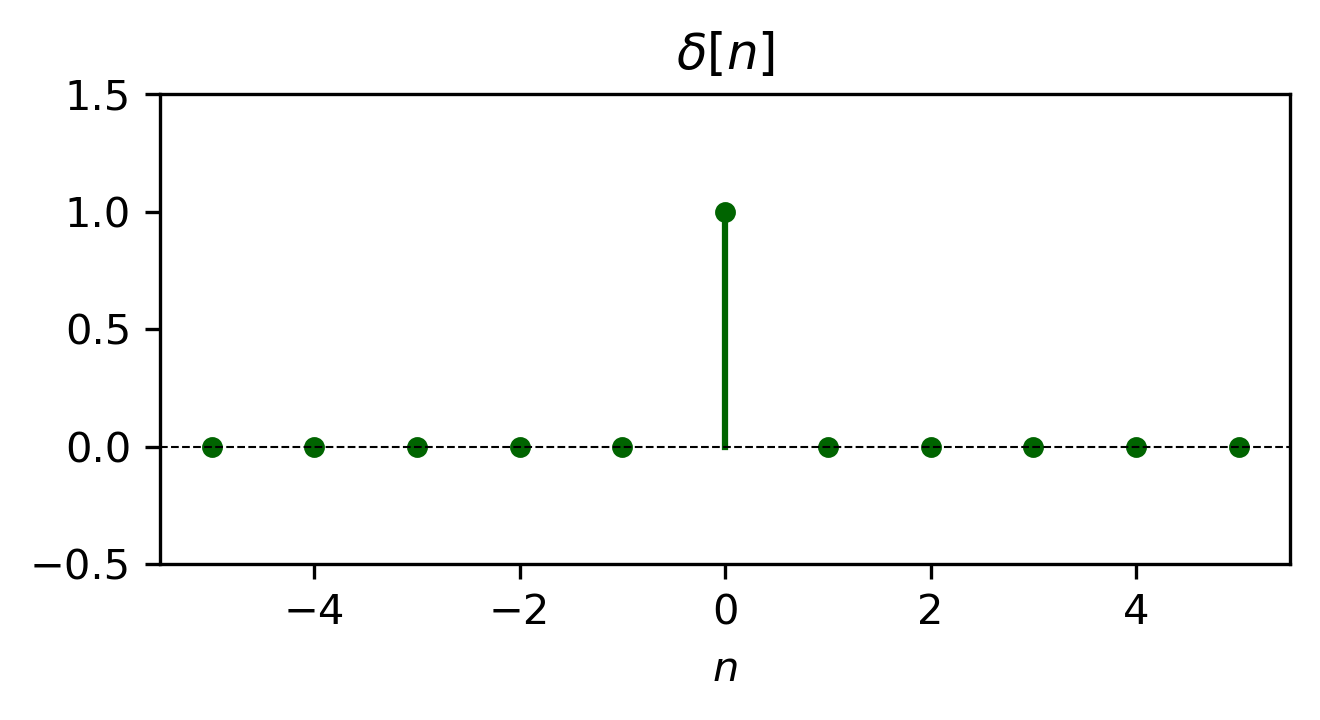

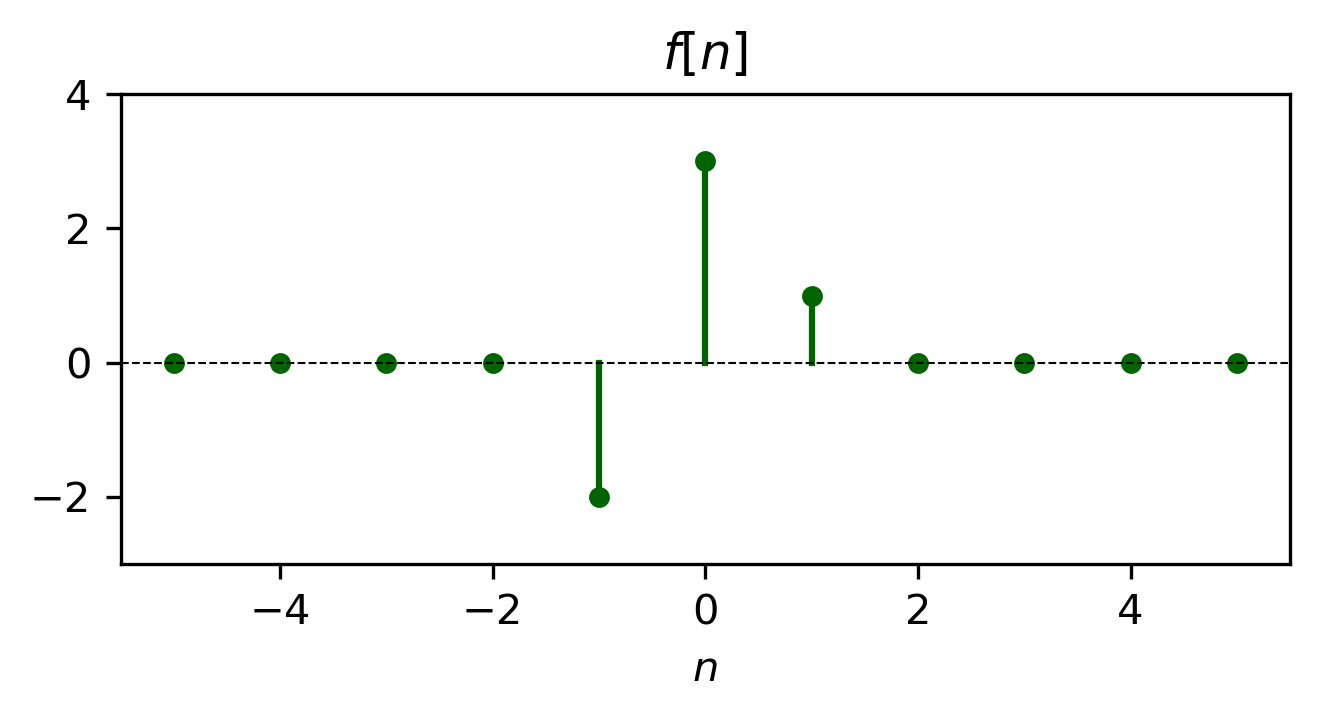

In [3]:
n = np.arange(-5, 6)    # n = -5, -4, ..., 5

# impulsna sekvenca delta[n]
delta = np.zeros(len(n))
delta[n == 0] = 1

sis.dijagram(n, delta, tip='uzorci',
         naslov=r'$\delta[n]$', ylim=(-0.5, 1.5)) 

# sekvenca f[n] = -2*delta[n+1] + 3*delta[n] + delta[n-1]
f = np.zeros(len(n))
f[n == -1] = -2
f[n ==  0] =  3
f[n ==  1] =  1

sis.dijagram(n, f, tip='uzorci', 
             naslov=r'$f[n]$', ylim=(-3, 4)) 

In [4]:
# =========================================================
# Kod 3.2 - Jedinicna sekvenca u[n]
# =========================================================

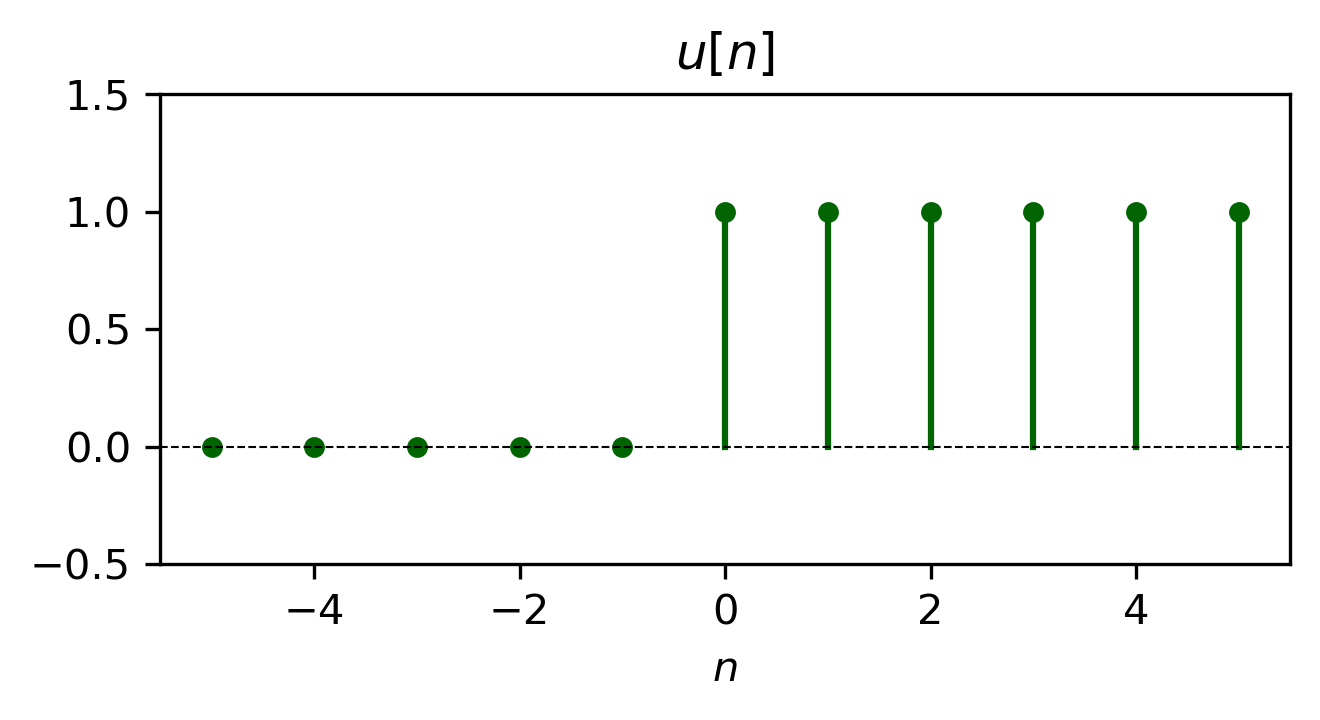

In [5]:
n = np.arange(-5, 6)

u = np.zeros(len(n))
u[n >= 0] = 1

sis.dijagram(n, u, tip='uzorci', 
             naslov='$u[n]$', ylim=(-0.5, 1.5))

In [6]:
# =========================================================
# Kod 3.3 - Diskretna rampa r[n] = n*u[n]
# =========================================================

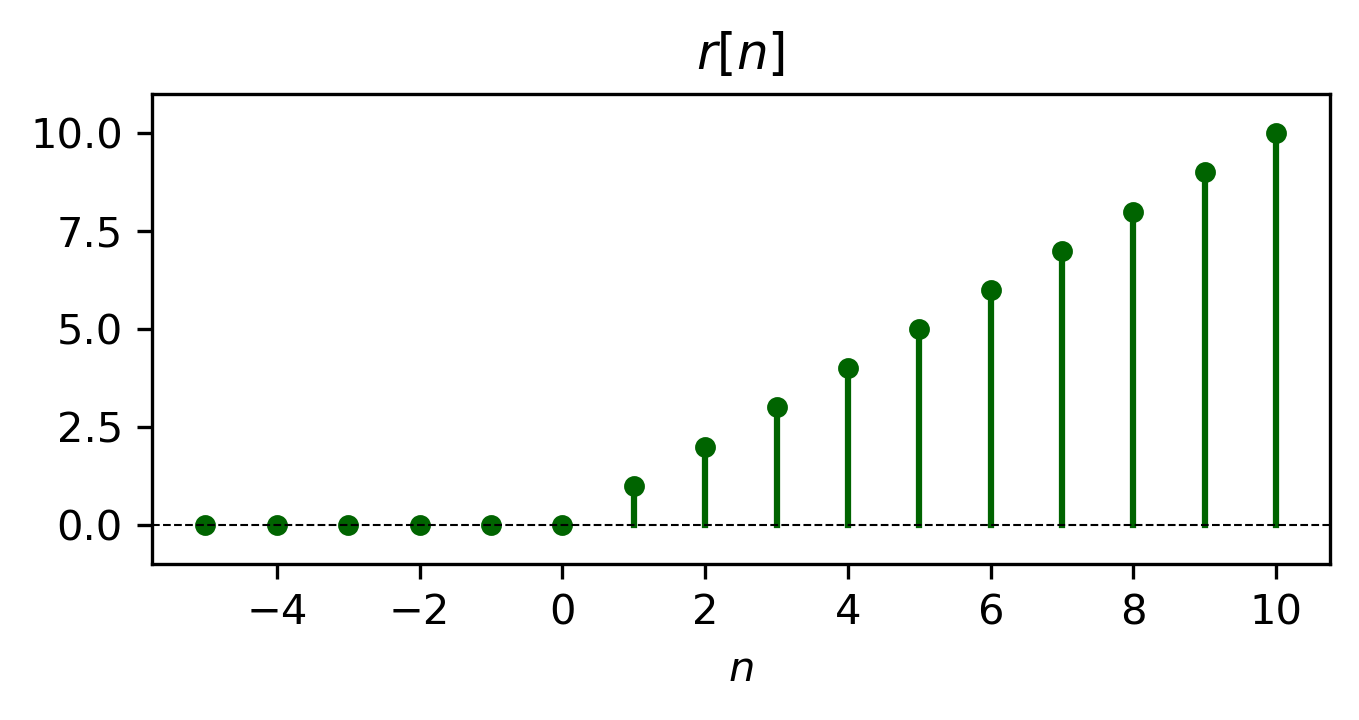

In [7]:
n = np.arange(-5, 11)
r = np.zeros(len(n))
r[n >= 0] = n[n >= 0]

sis.dijagram(n, r, tip='uzorci', 
             naslov='$r[n]$', ylim=(-1, 11))

In [8]:
# =========================================================
# Kod 3.4 - Realna kauzalna eksponencijalna sekvenca g[n]
# =========================================================

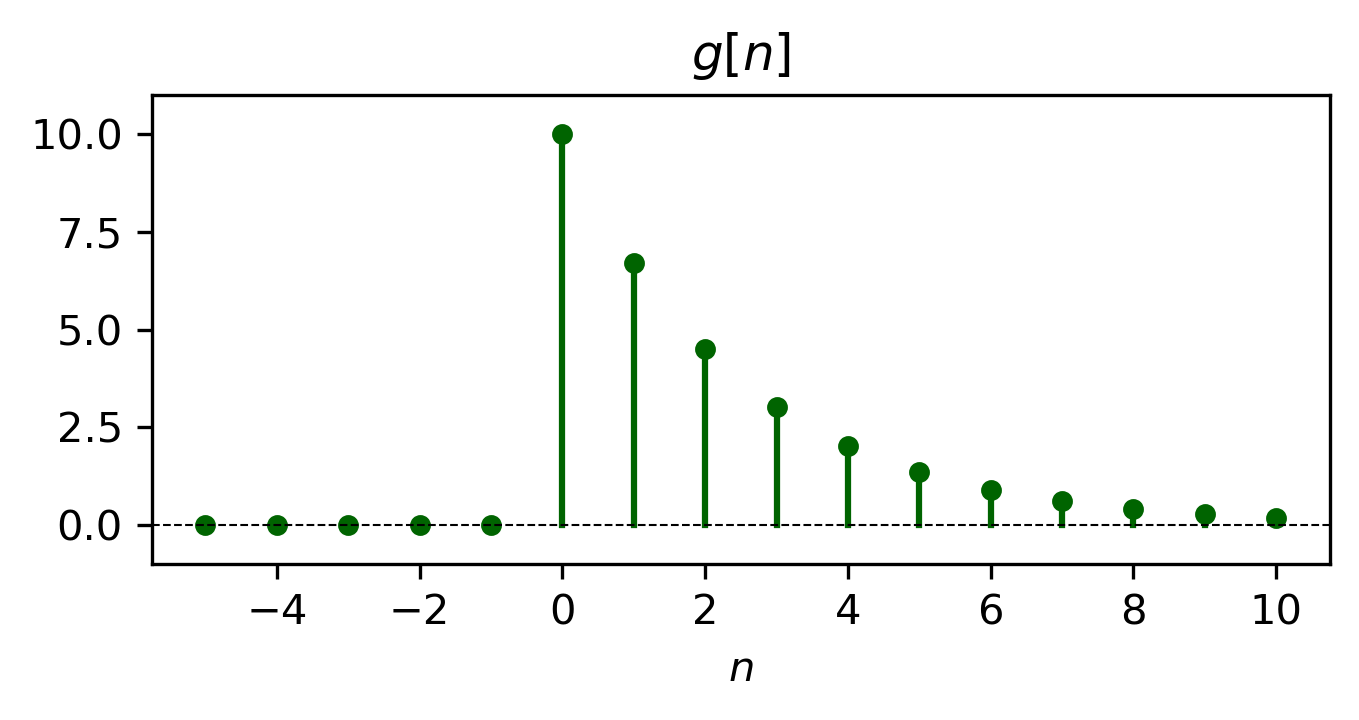

In [9]:
n = np.arange(-5, 11)
g = np.zeros(len(n))
g[n >= 0] = 10 * np.exp(-0.4 * n[n >= 0])

sis.dijagram(n, g, tip='uzorci', 
             naslov='$g[n]$', ylim=(-1, 11))

In [10]:
# =========================================================
# Kod 3.5 - Sinusna sekvenca, period N=20
# =========================================================

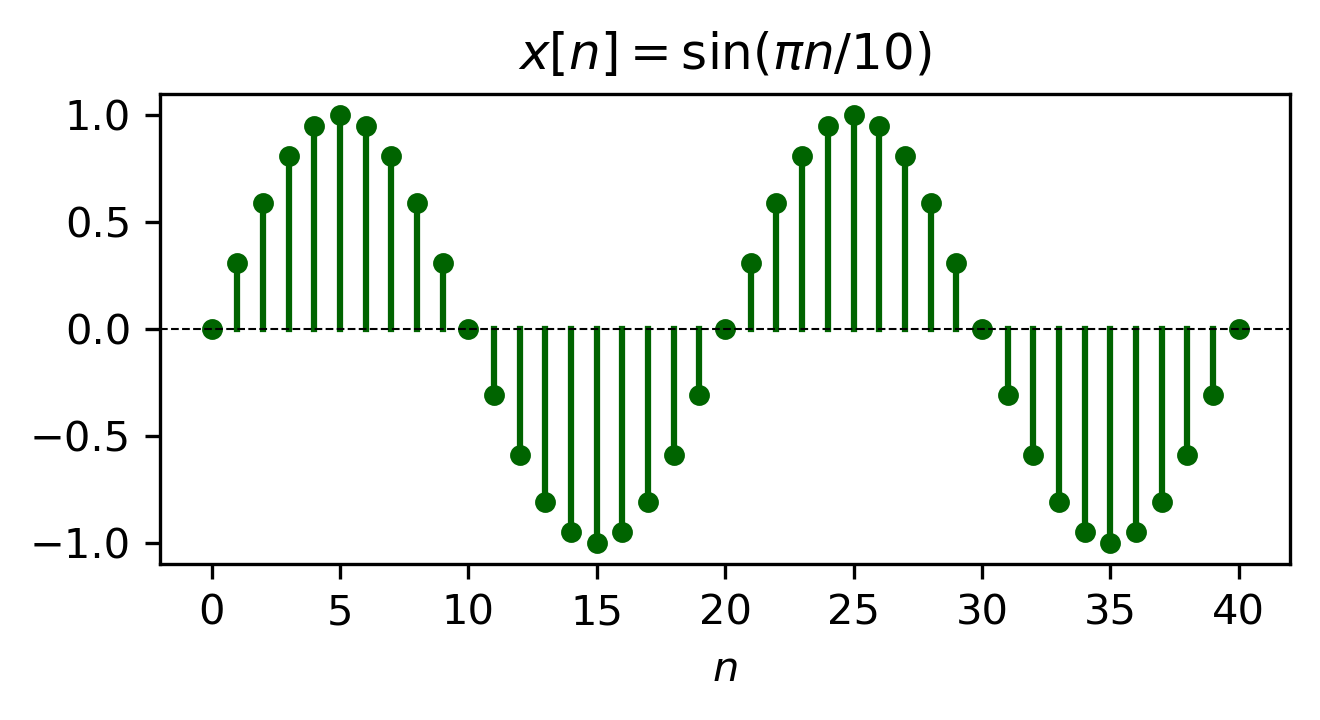

In [11]:
n = np.arange(0, 41)
s = np.sin(np.pi * n / 10)

sis.dijagram(n, s, 
             tip='uzorci', naslov=r'$x[n]=\sin(\pi n/10)$')

In [12]:
# =========================================================
# Kod 3.6 - Konvolucija diskretnih signala
# =========================================================

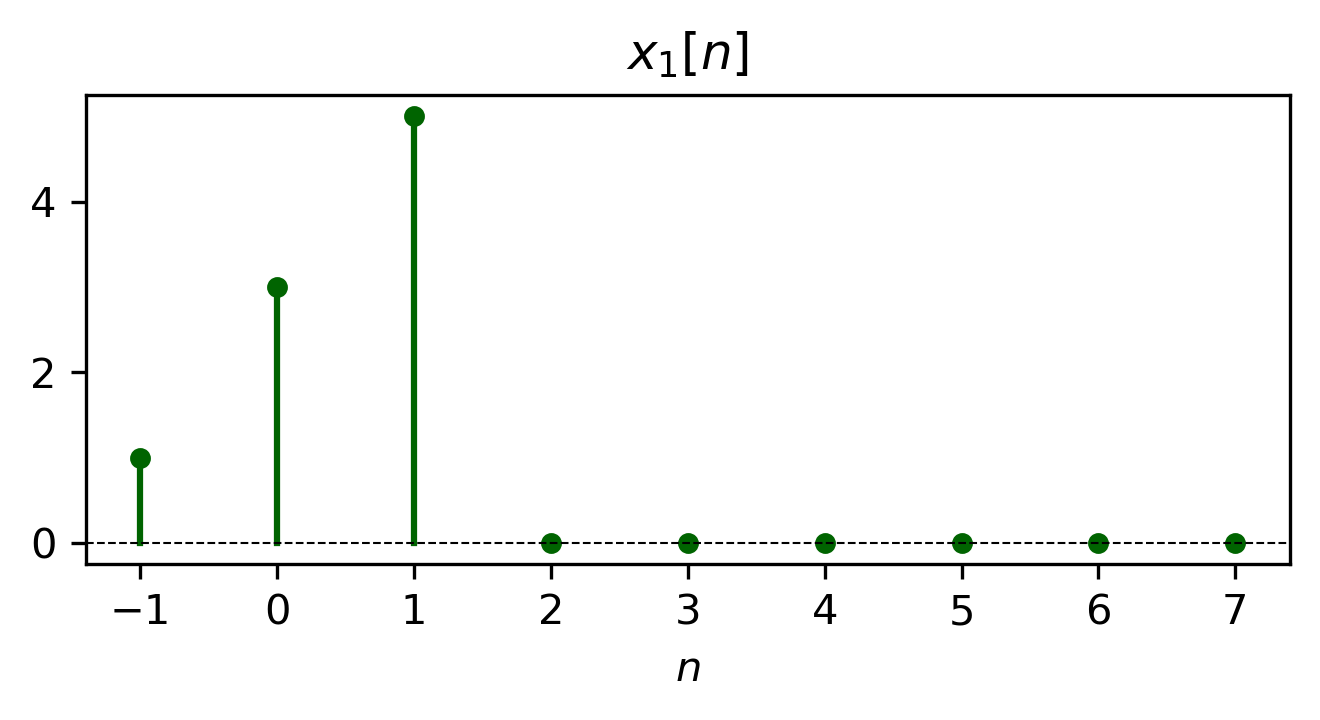

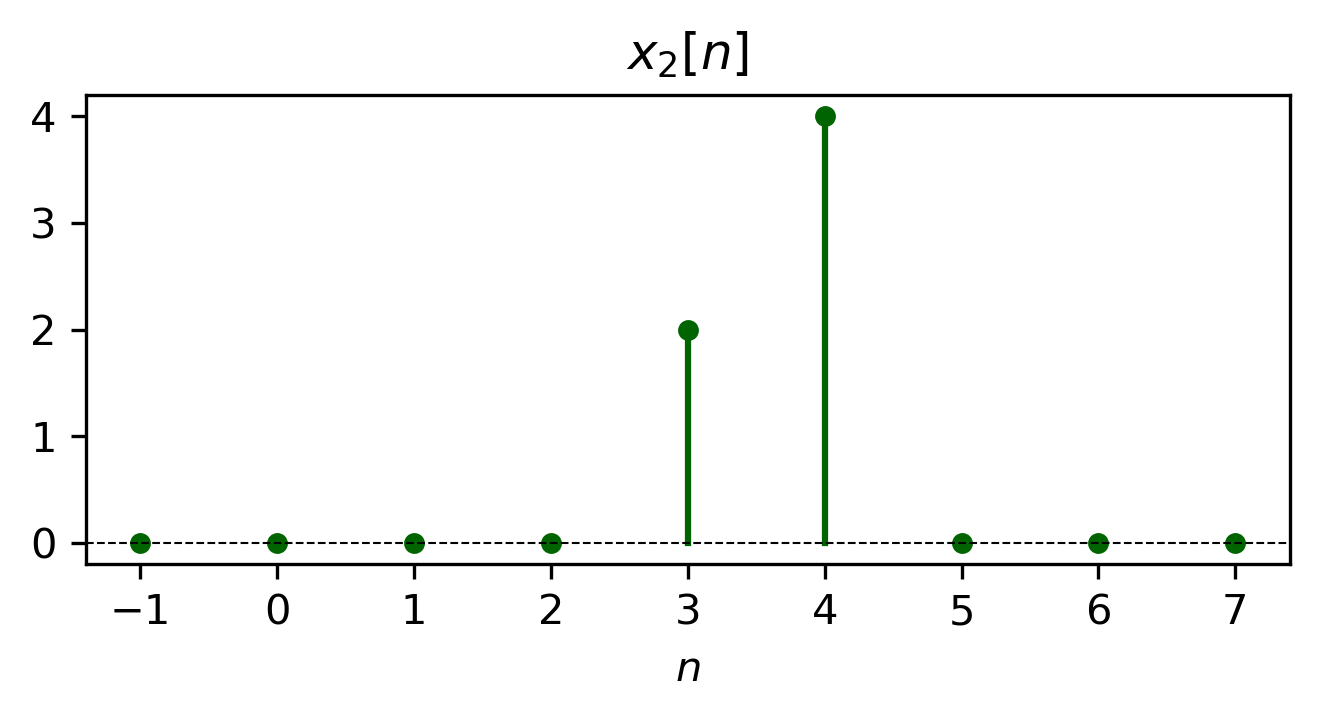

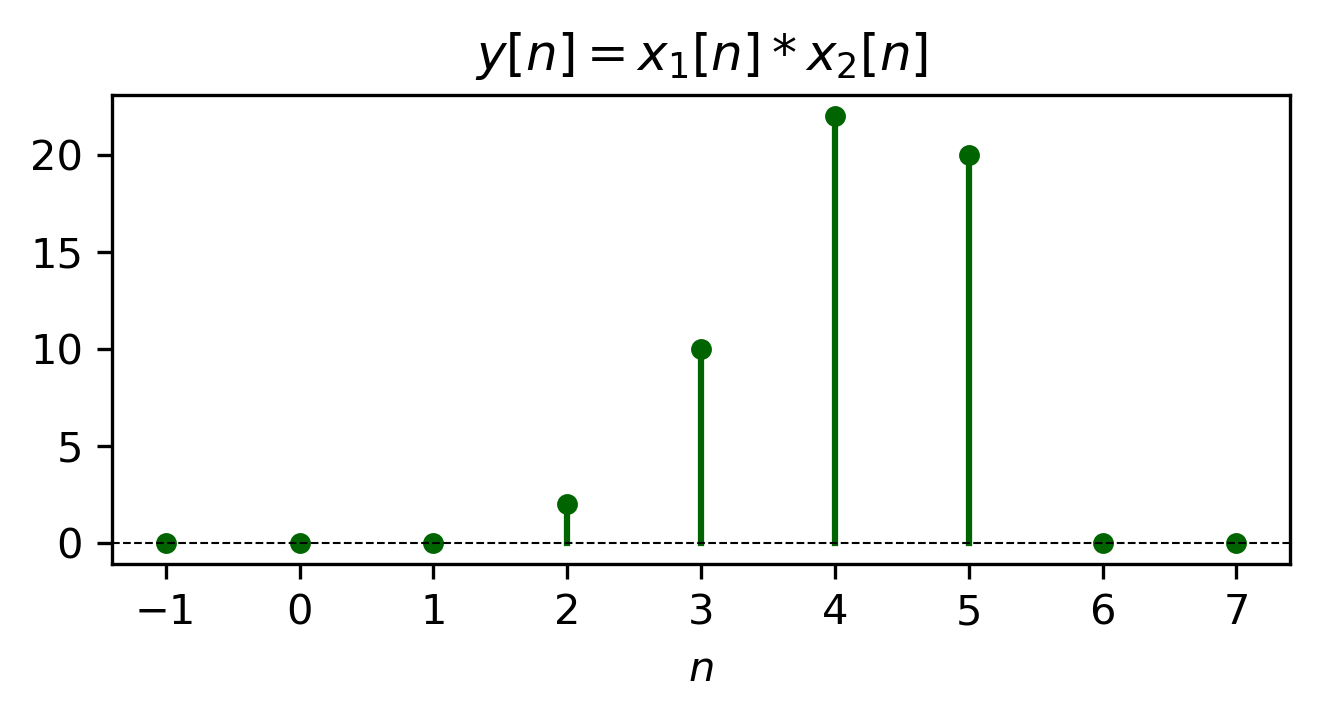

In [13]:
# definiranje sekvenci sa vremenskim bazama
n1 = np.arange(-1, 2)    # n1 = -1, 0, 1
x1 = np.array([1, 3, 5]) # x1[n] = delta[n+1] + 3*delta[n] + 5*delta[n-1]

n2 = np.arange(3, 5)     # n2 = 3, 4
x2 = np.array([2, 4])    # x2[n] = 2*delta[n-3] + 4*delta[n-4]

# konvolucija i odgovarajuca vremenska baza
y  = np.convolve(x1, x2)
ny = np.arange(n1[0] + n2[0], n1[-1] + n2[-1] + 1)

# zajednicki interval za prikaz
n_stem = np.arange(-1, 8)

def prosiri(x, nx, n_stem):
    """Prosiri sekvencu nulama na zadani interval."""
    x_stem = np.zeros(len(n_stem))
    for i, n in enumerate(nx):
        if n in n_stem:
            x_stem[np.where(n_stem == n)[0][0]] = x[i]
    return x_stem

x1_stem = prosiri(x1, n1, n_stem)
x2_stem = prosiri(x2, n2, n_stem)
y_stem  = prosiri(y,  ny, n_stem)

sis.dijagram(n_stem, x1_stem, tip='uzorci',
         naslov='$x_1[n]$')

sis.dijagram(n_stem, x2_stem, tip='uzorci',
         naslov='$x_2[n]$')

sis.dijagram(n_stem, y_stem, tip='uzorci', 
             naslov='$y[n] = x_1[n] * x_2[n]$')

In [14]:
# =========================================================
# Kod 3.7 - Impulsni i step odziv diskretnog sistema
#           y[n] - y[n-1] + 0.9*y[n-2] = x[n]
# =========================================================

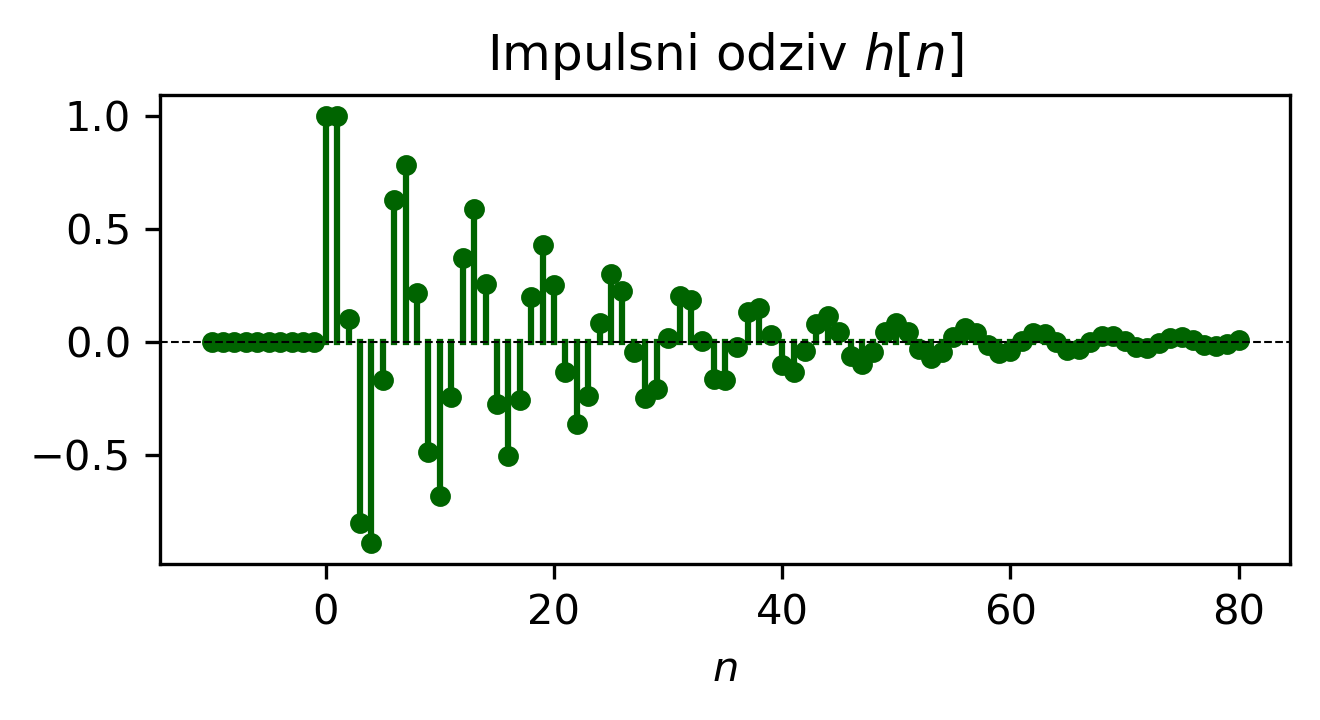

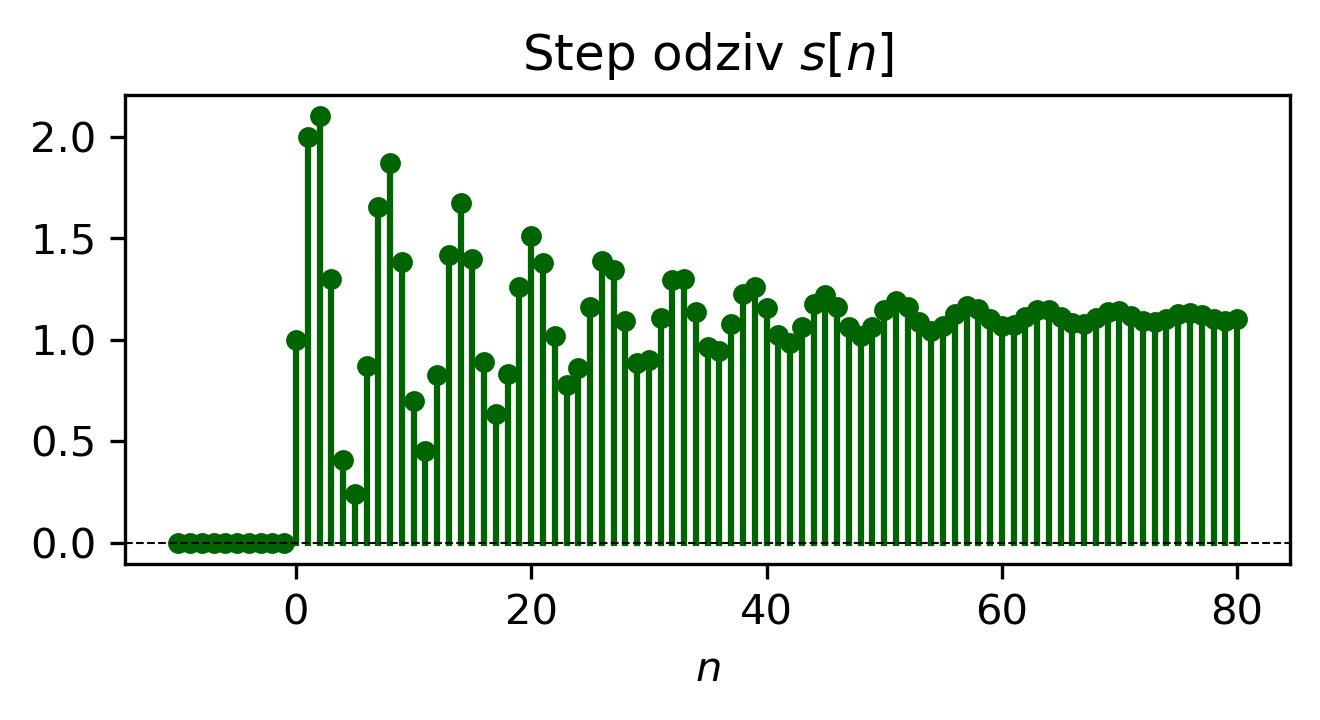

In [15]:
n      = np.arange(-10, 81)
N      = len(n)
offset = 10    # y[n] -> y[n+offset], tehnicki detalj Pythona

# a) impulsni odziv - ulaz je delta sekvenca
x_imp = np.zeros(N)
x_imp[n == 0] = 1

h = np.zeros(N + offset)
for k in range(N):
    h[k+offset] = (x_imp[k] + h[k+offset-1]
                   - 0.9 * h[k+offset-2])

# b) step odziv - ulaz je jedinicna sekvenca
x_step = np.zeros(N)
x_step[n >= 0] = 1

s = np.zeros(N + offset)
for k in range(N):
    s[k+offset] = (x_step[k] + s[k+offset-1]
                   - 0.9 * s[k+offset-2])

sis.dijagram(n, h[offset:offset+N], tip='uzorci',
         naslov='Impulsni odziv $h[n]$')

sis.dijagram(n, s[offset:offset+N], tip='uzorci',
         naslov='Step odziv $s[n]$')
    
 